# 03 · AD vs CN from pixels: PCA + linear and kernel classifiers

A baseline that uses no hand-crafted features at all. For each view:

- keep the pixels inside the brain mask (fitted on the training set);
- standardise, reduce with **PCA** and classify with **logistic regression**
  or an **RBF-kernel SVM**;
- tune the number of components and the regularisation with 5-fold
  stratified cross-validation, optimising **balanced accuracy** (the classes
  are imbalanced: 106 AD vs 631 CN);
- evaluate once on a held-out, stratified 30% test set. The split is made
  at the subject level and is shared by all views.

Besides one model per view, we also fit a model on the **concatenation of
the three views**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from adni_tau.data import ImageLoader, split_subjects
from adni_tau.evaluation import fit_evaluate_binary, plot_confusion_matrices, results_table
from adni_tau.paths import save_figure, save_table
from adni_tau.roi import brain_mask

plt.rcParams["figure.dpi"] = 90
VIEWS = ["axial", "coronal", "sagittal"]
loader = ImageLoader(views=VIEWS, classes=["AD", "CN"])
data = {view: loader.load_view(view) for view in VIEWS}

# Same subjects, in the same order, in every view.
for view in VIEWS[1:]:
    assert (data[view]["subject_ids"] == data[VIEWS[0]]["subject_ids"]).all()

y = data[VIEWS[0]]["classes"]
is_test = split_subjects(data[VIEWS[0]]["subject_ids"], y, test_size=0.3, random_state=42)
print(f"train: {np.sum(~is_test)} subjects ({np.sum(y[~is_test] == 'AD')} AD) | test: {is_test.sum()} subjects ({np.sum(y[is_test] == 'AD')} AD)")

train: 515 subjects (74 AD) | test: 222 subjects (32 AD)


## 1. Features: masked pixels

The brain mask is fitted on the training images only and then applied to
both sets.

In [2]:
X_by_view = {}
for view in VIEWS:
    d = data[view]
    mask = brain_mask(d["X"][~is_test], d["shape"]).reshape(-1) == 1
    X_by_view[view] = d["X"][:, mask]
    print(f"{view:>8}: {mask.sum()} pixels")
X_by_view["all views"] = np.hstack([X_by_view[v] for v in VIEWS])

   axial: 28343 pixels


 coronal: 26225 pixels


sagittal: 31345 pixels


## 2. Models

In [3]:
MODELS = {
    "PCA + logistic regression": (
        Pipeline([("scale", StandardScaler()), ("pca", PCA(random_state=0)), ("clf", LogisticRegression(max_iter=5000, class_weight="balanced"))]),
        {"pca__n_components": [5, 10, 20, 30, 50], "clf__C": [0.001, 0.01, 0.1, 1]},
    ),
    "PCA + RBF SVM": (
        Pipeline([("scale", StandardScaler()), ("pca", PCA(random_state=0)), ("clf", SVC(kernel="rbf", class_weight="balanced"))]),
        {"pca__n_components": [5, 10, 20, 30, 50], "clf__C": [0.1, 1, 10], "clf__gamma": ["scale"]},
    ),
}

rows, fitted = [], {}
for model_name, (pipe, grid) in MODELS.items():
    for view, X in X_by_view.items():
        res = fit_evaluate_binary(X[~is_test], y[~is_test], X[is_test], y[is_test], pipe, grid, positive_label="AD", n_jobs=2)
        fitted[(model_name, view)] = res
        rows.append({"model": model_name, "view": view, "cv_balanced_accuracy": res["cv_score"], "best_params": str(res["best_params"]), "metrics": res["metrics"]})

results = results_table(rows)
save_table(results, "03_pixel_pca_results")
results.drop(columns="best_params").round(3)

,model,view,cv_balanced_accuracy,accuracy,balanced_accuracy,macro_f1,roc_auc
0,PCA + logistic regression,axial,0.812,0.869,0.794,0.762,0.900
1,PCA + logistic regression,coronal,0.835,0.919,0.849,0.840,0.918
2,PCA + logistic regression,sagittal,0.797,0.842,0.778,0.731,0.843
3,PCA + logistic regression,all views,0.849,0.887,0.830,0.795,0.901
4,PCA + RBF SVM,axial,0.791,0.878,0.773,0.763,0.913
5,PCA + RBF SVM,coronal,0.833,0.847,0.768,0.730,0.848
6,PCA + RBF SVM,sagittal,0.769,0.829,0.666,0.662,0.809
7,PCA + RBF SVM,all views,0.803,0.883,0.750,0.756,0.882


## 3. Results

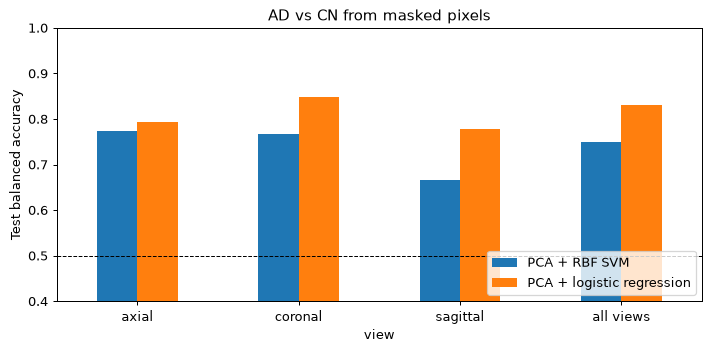

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
pivot = results.pivot(index="view", columns="model", values="balanced_accuracy").loc[VIEWS + ["all views"]]
pivot.plot.bar(ax=ax, rot=0, color=["tab:blue", "tab:orange"])
ax.axhline(0.5, color="k", linestyle="--", linewidth=0.8)
ax.set(ylabel="Test balanced accuracy", ylim=(0.4, 1), title="AD vs CN from masked pixels")
ax.legend(loc="lower right")
fig.tight_layout()
save_figure(fig, "03_pixel_pca_balanced_accuracy")

Best: PCA + logistic regression on coronal - balanced accuracy 0.849, ROC-AUC 0.918


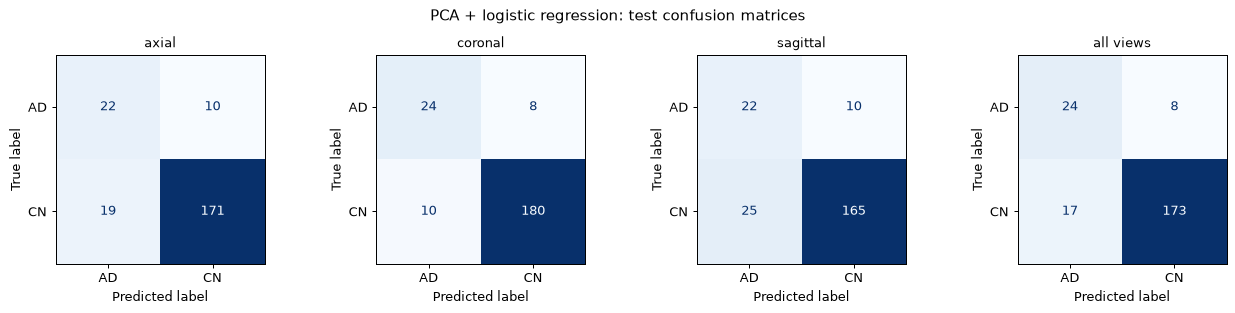

In [5]:
best = results.sort_values("balanced_accuracy", ascending=False).iloc[0]
print(f"Best: {best['model']} on {best['view']} - balanced accuracy {best['balanced_accuracy']:.3f}, ROC-AUC {best['roc_auc']:.3f}")
fig = plot_confusion_matrices({f"{v}": fitted[(best["model"], v)] for v in VIEWS + ["all views"]}, title=f"{best['model']}: test confusion matrices", ncols=4)
save_figure(fig, "03_pixel_pca_confusion")

## 4. What does the linear model look at?

For the logistic-regression pipeline the decision function is linear in the
pixels, so its weights can be mapped back to the image (scaler → PCA →
coefficients). Red pixels push towards AD.

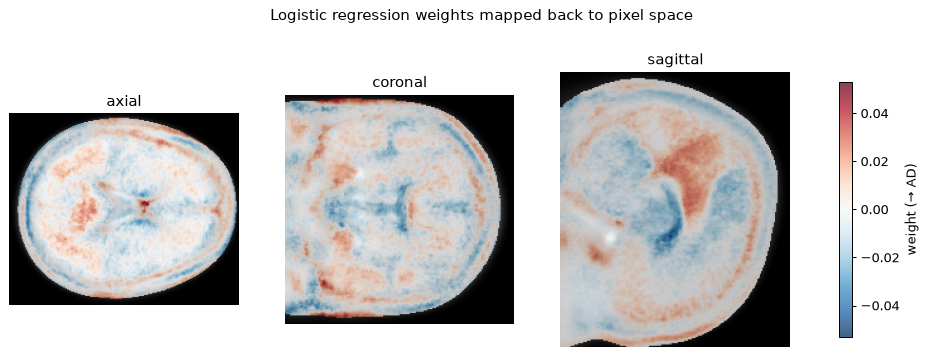

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, view in zip(axes, VIEWS):
    model = fitted[("PCA + logistic regression", view)]["model"]
    scale, pca, clf = model["scale"], model["pca"], model["clf"]
    sign = 1 if clf.classes_[1] == "AD" else -1
    w_pixels = sign * (clf.coef_ @ pca.components_).ravel() / scale.scale_
    d = data[view]
    mask = brain_mask(d["X"][~is_test], d["shape"]).reshape(-1) == 1
    full = np.zeros(mask.size)
    full[mask] = w_pixels
    lim = np.abs(full).max()
    ax.imshow(d["X"].mean(axis=0).reshape(d["shape"]), cmap="gray")
    im = ax.imshow(np.ma.masked_where(~mask, full).reshape(d["shape"]), cmap="RdBu_r", vmin=-lim, vmax=lim, alpha=0.75)
    ax.set_title(view)
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8, label="weight (→ AD)")
fig.suptitle("Logistic regression weights mapped back to pixel space")
save_figure(fig, "03_pixel_weight_maps")

**Reading the results.**

- **The coronal view is the most informative** (logistic regression:
  balanced accuracy 0.85, ROC-AUC 0.92). It cuts through the medial temporal
  lobes, where tau accumulates early in Alzheimer's disease.
- **Linear beats kernel.** Logistic regression matches or beats the RBF SVM
  in every view, which suggests the signal is essentially a linear shift in
  regional uptake. Strong regularisation (*C* = 0.001) is selected for most views.
- **Concatenating views does not help** (0.83 vs 0.85 for coronal alone):
  the extra 60,000 pixels add more noise than signal for 515 training
  subjects.
- Accuracy alone is misleading here: predicting "CN" for everyone already
  gives 86%. Balanced accuracy and ROC-AUC are the metrics to read.